## **#Importing necessary libraries for data manipulation**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib . pyplot as plt

### **#Load tables into the notebook**

In [ ]:
orders = pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/orders.csv")
products = pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/products.csv")
aisles= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/aisles.csv")
departments= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/departments.csv")
orderprodprior= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__prior.csv")
orderprodtrain= pd.read_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__train.csv")

## **#TABLE MEANING**

1. ORDERS: the "element" being studied in this table is the individual order, and the row contains all measurements (variables) related to that single occurrence.One row represents a single customer order, which is a discrete transaction event.
2. PRODUCTS: The element being measured in this table is the individual product, and the row provides the complete set of measurements for that element. One row represents a single unique product or item in the organization's catalog.
3. ORDER_PRODUCTS_PRIOR: One row represents a single product included as an item within a specific order eg the first five rows all share the same order_id (2), demonstrating that order #2 contained at least five different products, with each product being described by its own distinct row in this table

ORDERS TABLE QUESTIONS:

-On which day of the week do customers shop more frequently?

-What are the peak hours for order activity?

-What is the typical time elapsed between customer’s purchase?


## **#Summary statistics for Numerical Variables**

**DAYS SINNCE PRIOR ORDER**

---



In [ ]:
orders['days_since_prior_order'].describe()

,days_since_prior_order
count,3.214874e+06
mean,1.111484e+01
std,9.206737e+00
min,0.000000e+00
25%,4.000000e+00
50%,7.000000e+00
75%,1.500000e+01
max,3.000000e+01


Histogram

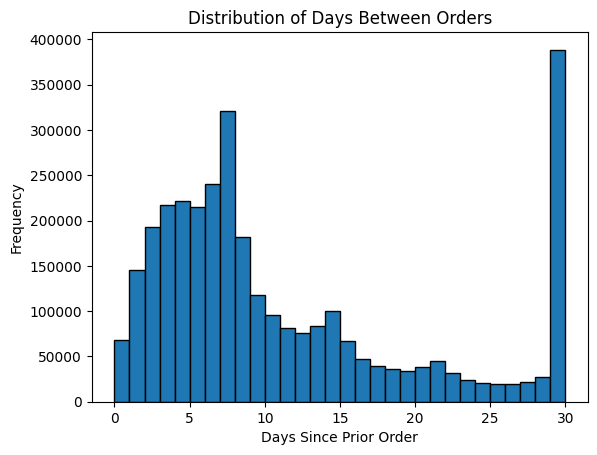

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.hist(orders['days_since_prior_order'].dropna(), bins=30, edgecolor='black')
plt.xlabel("Days Since Prior Order")
plt.ylabel("Frequency")
plt.title("Distribution of Days Between Orders")
plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/days_between_orders.png", bbox_inches='tight')

 Notable Features:

-Prominent peak at the 7-day mark

  -Huge decline after day 7.

  -A secondary, smaller peak is visible around 14 to 15 days.
  
  -Massive spike at exactly 30 days, which represents the highest frequency in the entire dataset.

  

*ORDER NUMBER*

---



In [ ]:
orders['order_number' ].describe()

,order_number
count,3.421083e+06
mean,1.715486e+01
std,1.773316e+01
min,1.000000e+00
25%,5.000000e+00
50%,1.100000e+01
75%,2.300000e+01
max,1.000000e+02


Histogram

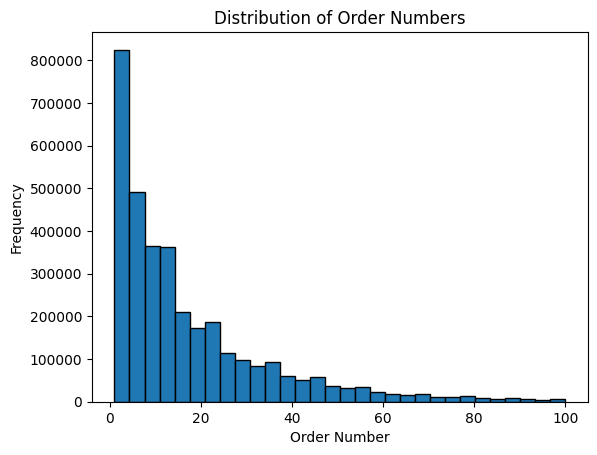

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.hist(orders['order_number'].dropna(),bins=30, edgecolor='black')
plt.xlabel("Order Number")
plt.ylabel("Frequency")
plt.title("Distribution of Order Numbers")
plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/order_num.png", bbox_inches='tight')

1. Notable Features:

  -The highest frequency occurs at the very beginning of the X-axis (order numbers 1–5)
  
  -There is a steady, non-linear decline in frequency as the order number increases.

**ORDER HOUR OF DAY**

---



In [ ]:
orders['order_hour_of_day'].describe()

,order_hour_of_day
count,3.421083e+06
mean,1.345202e+01
std,4.226088e+00
min,0.000000e+00
25%,1.000000e+01
50%,1.300000e+01
75%,1.600000e+01
max,2.300000e+01


Histogram

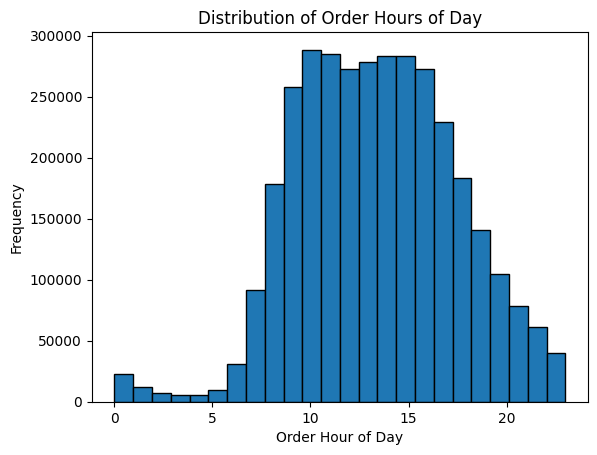

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.hist(orders['order_hour_of_day'].dropna(), bins=24, edgecolor='black')
plt.xlabel("Order Hour of Day")
plt.ylabel("Frequency")
plt.title("Distribution of Order Hours of Day")
plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/order_hr_of_day.png", bbox_inches='tight')

1. Notable Features:

  -Ordering remains at its highest and most stable around 10:00–16:00

  -Peak Hour at 10:00
  
  -There is morning dormancy between 1 am and 5am

## **#CATEGORICAL DATA UNIVARIATE ANALYSIS**

ORDER DAY OF WEEK

---



Frequency count

In [ ]:
orders['order_dow'].value_counts()

,count
order_dow,
0,600905
1,587478
2,467260
5,453368
6,448761
3,436972
4,426339


Based on the frequency count it is clear day 0 has the highest frequency. Customers are most common during this day.

Visualisation

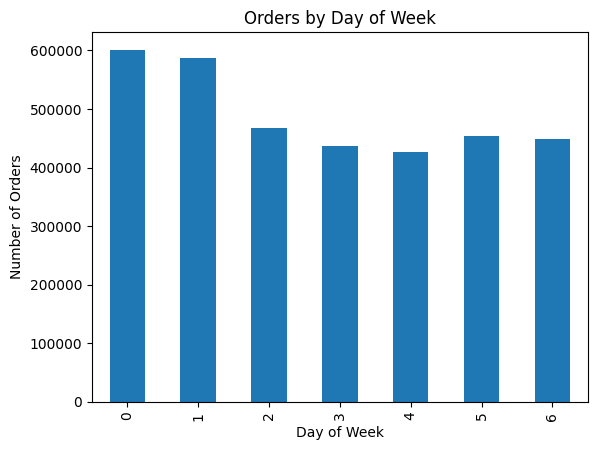

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.hist(orders['days_since_prior_order'].dropna(), bins=30, edgecolor='black')
plt.xlabel("Days Since Prior Order")
plt.ylabel("Frequency")
plt.title("Distribution of Days Between Orders")
plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/days_between_orders.png", bbox_inches='tight')

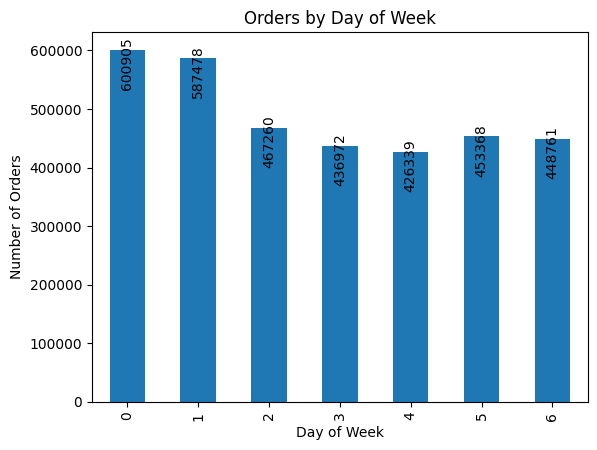

<Figure size 640x480 with 0 Axes>

In [ ]:
dow = orders['order_dow'].value_counts().sort_index().plot(kind='bar')
plt.xlabel("Day of Week")
plt.ylabel("Number of Orders")
plt.title("Orders by Day of Week")

# To add frequency labels inside the bars vertically
for p in dow.patches:
    dow.annotate(str(p.get_height()), (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, -10), textcoords='offset points', rotation=90, color='black')

plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/orders_by_day_of_week.png", bbox_inches='tight')

Dominant Categories (Peak Activity): The most frequent ordering days are Day 0 (Sunday) with 600,905 orders and Day 1 (Monday) with 587,478 orders. These two days represent the absolute peak of customer activity for the organisation.

Rare Categories (Lowest Activity): The days with the lowest transaction volume are Day 4 (Thursday) with 426,339 orders and Day 3 (Wednesday) with 436,972 orders. These mid-week days represent the "valleys" in the company's weekly operational cycle.

These results align with standard expectations for a grocery or shipment service. Typically, consumers use the weekend (Sunday) and the start of the work week (Monday) to restock their households for the coming days. Conversely, activity often dips mid-week before rising again as the next weekend approaches.

This information answers the question  "On which day of the week do customers shop most frequently?"
Sunday stands out as the most frequented day. Management should use this information for staffing and logistics planning, ensuring maximum warehouse personnel and delivery drivers are available at the start of the week to handle the surge in demand.

Eval Set

---



**"What is the proportional distribution of orders across the 'prior', 'train', and 'test' dataset partitions?"**

Frequency count

In [ ]:
orders['eval_set'].value_counts()

,count
eval_set,
prior,3214874
train,131209
test,75000


*   Prior: Approximately 93.97%
*   Train: Approximately 3.84%

*   Test: Approximately 2.19%


Visualisation

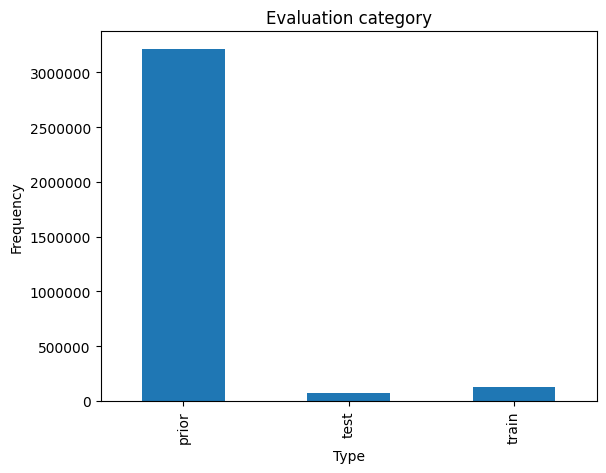

<Figure size 640x480 with 0 Axes>

In [ ]:
orders['eval_set'].value_counts().sort_index().plot(kind='bar')
plt.xlabel("Type")
plt.ylabel("Frequency")
plt.title("Evaluation category")
plt.ticklabel_format(style='plain', axis='y')
plt.show()
plt.savefig("../content/drive/MyDrive/ADA2026_Instacart_Project/outputs/figures/eval_freq.png", bbox_inches='tight')

Dominant Category: The "prior" set is the overwhelmingly dominant category, containing 3,214,874 orders. Visually, the bar for "prior" towers over the other two categories, representing the vast majority of the company's historical data.

Rare Categories: The "train" and "test" categories are relatively rare. The "train" set contains 131,209 orders, while the "test" set is the smallest with 75,000 orders.

These results align perfectly with standard expectations for the Knowledge Discovery (KDD) process and predictive modelling.
It is expected that the "prior" set be the largest because it is used for descriptive analytics to establish stable behavioral baselines for customers—such as identifying peak hours and typical time between orders—before any modeling begins.


# END OF T2

**#Inspect Data**

1.ORDERS

In [ ]:
orders.head()

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


In [ ]:
orders.info()

In [ ]:
orders.shape

**2. PRODUCTS**

In [ ]:
products.head()
products.info()
products.shape

,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


**3. ORDER_PRODUCTS_PRIOR**

In [ ]:
orderprodprior.head()
orderprodprior.info()
orderprodprior.shape

,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0


4.ORDER_PRODUCTS_TRAIN

In [ ]:
orderprodtrain.head()
orderprodtrain.info()
orderprodtrain.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1384617 entries, 0 to 1384616
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype
---  ------             --------------    -----
 0   order_id           1384617 non-null  int64
 1   product_id         1384617 non-null  int64
 2   add_to_cart_order  1384617 non-null  int64
 3   reordered          1384617 non-null  int64
dtypes: int64(4)
memory usage: 42.3 MB


5.AISLES

In [ ]:
aisles.head()
aisles.info()
aisles.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


6.DEPARTMENTS

In [ ]:
departments.head()
departments.info()
departments.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 468.0+ bytes


**#CHECK MISSING VALUES**

In [ ]:
orders.isna().sum().sort_values(ascending=False)

,0
days_since_prior_order,206209
user_id,0
order_id,0
eval_set,0
order_number,0
order_dow,0
order_hour_of_day,0


In [ ]:
aisles.isna().sum().sort_values(ascending=False)

,0
aisle_id,0
aisle,0


In [ ]:
departments.isna().sum().sort_values(ascending=False)

,0
department_id,0
department,0


In [ ]:
orderprodprior.isna().sum().sort_values(ascending=False)

,0
order_id,0
product_id,0
add_to_cart_order,0
reordered,0


In [ ]:
orderprodtrain.isna().sum().sort_values(ascending=False)

,0
order_id,0
product_id,0
add_to_cart_order,0
reordered,0


In [ ]:
products.isna().sum().sort_values(ascending=False)

,0
product_id,0
product_name,0
aisle_id,0
department_id,0


**#DATA DICTIONARY**

In [ ]:
variables_data = {
    'Table': ['ORDERS', 'ORDERS', 'ORDERS', 'ORDERS', 'ORDERS', 'ORDERS',
              'PRODUCTS', 'PRODUCTS', 'PRODUCTS', 'AISLES',
              'DEPARTMENTS', 'ORDER_PRODUCTS_PRIOR', 'ORDER_PRODUCTS_PRIOR'],
    'Column': ['user_id', 'order_id', 'eval_set', 'order_number', 'order_dow', 'order_hour_of_day',
               'product_id', 'product_name', 'aisle_id', 'aisle',
               'department', 'order_id', 'product_id'],
    'Meaning': [
        'Unique identifier for each customer',
        'Unique identifier for each order',
        'Indicator of whether this order is in the training, test, or prior datasets',
        'The sequence order number for this user (1st order, 2nd order, etc.)',
        'Day of week when the order was placed (0-6, where 0=Sunday)',
        'Hour of the day when the order was placed (0-23)',
        'Unique identifier for each product',
        'Name/description of the product',
        'Unique identifier for the aisle category',
        'Name of the aisle/subcategory',
        'Name of the product department',
        'References the order that contains product items',
        'References the product that was ordered'
    ],
    'Data Type': [
        'Integer (int64)',
        'Integer (int64)',
        'String/Categorical',
        'Integer (int64)',
        'Integer (int64)',
        'Integer (int64)',
        'Integer (int64)',
        'String/Text',
        'Integer (int64)',
        'String/Categorical',
        'String/Categorical',
        'Integer (int64)',
        'Integer (int64)'
    ],
    'Notes': [
        'Ranges from 0 to maximum user ID; unique per customer',
        'Unique order identifier; foreign key in ORDER_PRODUCTS tables',
        'Values: "prior", "train", "test" - indicates dataset split',
        'Sequential numbering starting from 1 for each user',
        'Integer 0-6 representing days; useful for day-of-week analysis',
        'Integer 0-23 in 24-hour format; useful for temporal analysis',
        'Unique product identifier; links to PRODUCTS table',
        'Product description/label; text-based information',
        'Foreign key linking to AISLES table',
        'Subcategory of products (e.g., "vegetables", "bakery")',
        'High-level product category (e.g., "produce", "dairy")',
        'Foreign key to ORDERS table; enables linking orders to products',
        'Foreign key to PRODUCTS table; identifies which product was purchased'
    ]
}

# Creating DataFrame
variable_table = pd.DataFrame(variables_data)

# For Displaying the table
print("=" * 150)
print("INSTACART DATASET: VARIABLE DESCRIPTION TABLE")
print("=" * 150)
print(variable_table.to_string(index=False))
print("=" * 150)

INSTACART DATASET: VARIABLE DESCRIPTION TABLE
               Table            Column                                                                     Meaning          Data Type                                                                 Notes
              ORDERS           user_id                                         Unique identifier for each customer    Integer (int64)                 Ranges from 0 to maximum user ID; unique per customer
              ORDERS          order_id                                            Unique identifier for each order    Integer (int64)         Unique order identifier; foreign key in ORDER_PRODUCTS tables
              ORDERS          eval_set Indicator of whether this order is in the training, test, or prior datasets String/Categorical            Values: "prior", "train", "test" - indicates dataset split
              ORDERS      order_number        The sequence order number for this user (1st order, 2nd order, etc.)    Integer (int64)     

**#INTERIM COLAB**

In [ ]:
orders.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/orders.csv", index=False)
products.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/products.csv", index=False)
aisles.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/aisles.csv", index=False)
departments.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/departments.csv", index=False)
orderprodprior.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__prior.csv", index=False)
orderprodtrain.to_csv("../content/drive/MyDrive/ADA2026_Instacart_Project/data/raw/instacart/order_products__train.csv", index=False)

**#MARKDOWN Description**

1.The Dataset represents data of a Schipment company with supplies such as PlugTech which sells refurbished Data.


2.-Customer Segmentation: Managers can use Cluster Analysis to group customers based on which Aisles or Departments they frequent, allowing for targeted promotional campaigns
-Departmental Staffing: Descriptive analytics on Orders can highlight peak times for specific Departments, helping managers determine optimal staffing levels to handle order surges
-Demand Forecasting: The company can use time-series analysis on prior orders to forecast consumption of fast-moving products, ensuring the right amount of inventory is stocked to avoid stock-outs

3. Descriptive analytics:
   ORDERS Table, PRODUCTS, AISLES,ORDER_PRODUCTS_PRIOR Table and DEPARTMENTS Tables

   Predictive Analytics:
   ORDER_PRODUCTS_PRIOR and ORDER_PRODUCTS_TRAIN Tables

   Prescriptive Analytics:
   ORDERS, PRODUCTS, AISLES, DEPARTMENTS